<a href="https://colab.research.google.com/github/Michruiz2710/skin-cancer-detection-APPR/blob/main/notebooks/03_entrenamiento_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Entrenamiento v4 — DenseNet201

**Proyecto APPR — Detección de Cáncer de Piel**

Correcciones sobre v3:

| # | Problema en v3 | Corrección en v4 |
|---|---|---|
| 1 | Callbacks monitoreaban `val_accuracy` → el modelo predecía siempre `nv` y subía accuracy sin aprender | Monitorear `val_macro_f1` — penaliza ignorar clases minoritarias |
| 2 | Class weights todos en 1.0 (balanceo previo los igualó) → sin penalización por ignorar clases raras | Class weights basados en distribución **original** del dataset |


## 1 · Configuración del entorno

In [ ]:
import os
from google.colab import drive

!usr/bin/fusermount -u /content/drive 2>/dev/null || true
if os.path.exists('/content/drive') and os.listdir('/content/drive') == []:
    os.rmdir('/content/drive')

drive.mount('/content/drive', force_remount=True)
print('✅ Drive montado')

Mounted at /content/drive
✅ Drive montado


In [ ]:
!pip install -q datasets
print('✅ datasets instalado')

✅ datasets instalado


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from sklearn.utils import resample
from sklearn.utils.class_weight import compute_class_weight
print('TF:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TF: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2 · Rutas y configuración

In [ ]:
DRIVE_BASE = '/content/drive/MyDrive/skin-cancer-APPR'
MODELS_DIR = os.path.join(DRIVE_BASE, 'models')
DATA_DIR   = os.path.join(DRIVE_BASE, 'data')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(DATA_DIR,   exist_ok=True)

IMG_SIZE         = 224
BATCH_SIZE       = 32
TARGET_PER_CLASS = 2000
NUM_CLASSES      = 7

EPOCHS_PHASE1    = 30
LR_PHASE1        = 1e-3

EPOCHS_PHASE2A   = 20
LR_PHASE2A       = 1e-5

EPOCHS_PHASE2B   = 20
LR_PHASE2B       = 5e-6

UNFREEZE_PHASE2A = 50
UNFREEZE_PHASE2B = 100
DROPOUT_RATE     = 0.5

CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

HF_TO_SHORT = {
    'melanocytic_Nevi':              'nv',
    'melanoma':                      'mel',
    'benign_keratosis-like_lesions': 'bkl',
    'basal_cell_carcinoma':          'bcc',
    'actinic_keratoses':             'akiec',
    'vascular_lesions':              'vasc',
    'dermatofibroma':                'df',
}
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

print('Configuración v4 cargada ✅')
print(f'  Fase 1 : {EPOCHS_PHASE1} épocas, lr={LR_PHASE1}')
print(f'  Fase 2a: {EPOCHS_PHASE2A} épocas, lr={LR_PHASE2A}, descongelar {UNFREEZE_PHASE2A} capas')
print(f'  Fase 2b: {EPOCHS_PHASE2B} épocas, lr={LR_PHASE2B}, descongelar {UNFREEZE_PHASE2B} capas')

Configuración v4 cargada ✅
  Fase 1 : 30 épocas, lr=0.001
  Fase 2a: 20 épocas, lr=1e-05, descongelar 50 capas
  Fase 2b: 20 épocas, lr=5e-06, descongelar 100 capas


## 3 · Carga del dataset desde Drive

In [ ]:
from datasets import load_dataset
from PIL import Image as PILImage

MEAN_NP = np.array(MEAN, dtype=np.float32)
STD_NP  = np.array(STD,  dtype=np.float32)

def convert_and_save(split):
    x_path = os.path.join(DATA_DIR, f'{split}_X.npy')
    y_path = os.path.join(DATA_DIR, f'{split}_y.npy')
    if os.path.exists(x_path) and os.path.exists(y_path):
        print(f'[{split}] Cargando desde Drive...')
        X = np.load(x_path)
        y = np.load(y_path)
        print(f'[{split}] X={X.shape}, y={y.shape} ✅')
        return X, y
    print(f'[{split}] No encontrado, convirtiendo desde HuggingFace...')
    hf_split = hf_ds[split]
    n = len(hf_split)
    X = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    y = np.zeros(n, dtype=np.int32)
    for i in range(n):
        sample = hf_split[i]
        img = sample['image'].convert('RGB').resize((IMG_SIZE, IMG_SIZE), PILImage.BILINEAR)
        arr = np.array(img, dtype=np.float32) / 255.0
        X[i] = (arr - MEAN_NP) / STD_NP
        y[i] = CLASS_INDEX[HF_TO_SHORT.get(sample['dx'], sample['dx'])]
        if i % 500 == 0:
            print(f'  {i}/{n}...')
    np.save(x_path, X)
    np.save(y_path, y)
    print(f'[{split}] Guardado ✅')
    return X, y

train_x_exists = os.path.exists(os.path.join(DATA_DIR, 'train_X.npy'))
if not train_x_exists:
    hf_ds = load_dataset('marmal88/skin_cancer')
else:
    hf_ds = None

X_train_raw, y_train_raw = convert_and_save('train')
X_val_arr,   y_val       = convert_and_save('validation')
X_test_arr,  y_test      = convert_and_save('test')

print(f'\nDistribución original de clases (train):')
for i, name in enumerate(CLASS_NAMES):
    n = np.sum(y_train_raw == i)
    print(f'  {name}: {n}')

README.md:   0%|          | 0.00/3.24k [00:00<?, ?B/s]

data/train-00000-of-00005-7eed077f2f8e6d(…): reconstructing file:   0%|          |  0.00B /  521MB            

data/train-00000-of-00005-7eed077f2f8e6d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00005-50ba64fd20294b(…): reconstructing file:   0%|          |  0.00B /  525MB            

data/train-00001-of-00005-50ba64fd20294b(…): downloading bytes:           |  0.00B            

data/train-00002-of-00005-36c02a25cbdd54(…): reconstructing file:   0%|          |  0.00B /  527MB            

... (11 outputs left out)

Generating train split:   0%|          | 0/9577 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2492 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1285 [00:00<?, ? examples/s]

[train] No encontrado, convirtiendo desde HuggingFace...
  0/9577...
  500/9577...
  1000/9577...
  1500/9577...
  2000/9577...
  2500/9577...
  3000/9577...
  3500/9577...
  4000/9577...
  4500/9577...
  5000/9577...
  5500/9577...
  6000/9577...
  6500/9577...
  7000/9577...
  7500/9577...
  8000/9577...
  8500/9577...
  9000/9577...
  9500/9577...
[train] Guardado ✅
[validation] No encontrado, convirtiendo desde HuggingFace...
  0/2492...
  500/2492...
  1000/2492...
  1500/2492...
  2000/2492...
[validation] Guardado ✅
[test] No encontrado, convirtiendo desde HuggingFace...
  0/1285...
  500/1285...
  1000/1285...
[test] Guardado ✅

Distribución original de clases (train):
  akiec: 315
  bcc: 487
  bkl: 1048
  df: 110
  mel: 1076
  nv: 6405
  vasc: 136


## 3b · Balanceo e índices

**v4:** los `class_weights` se calculan sobre la distribución **original** (antes del balanceo),
no sobre el dataset balanceado. Así el modelo paga más por ignorar clases raras como `df` o `vasc`.

In [ ]:
# ── v4: class_weights basados en distribución ORIGINAL ──────────────────────
# Esto hace que equivocarse en df (110 imgs) cueste mucho más que en nv (6405 imgs)
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=y_train_raw          # distribución original, no balanceada
)
class_weights = {i: w for i, w in enumerate(class_weights_arr)}

print('Class weights (basados en distribución original):')
for i, name in enumerate(CLASS_NAMES):
    n = np.sum(y_train_raw == i)
    print(f'  {name:6s}: {n:5d} imgs → peso {class_weights[i]:.2f}')

# ── Balanceo: solo guardamos ÍNDICES ────────────────────────────────────────
balanced_idx = []
for label_idx in range(NUM_CLASSES):
    idx_class = np.where(y_train_raw == label_idx)[0]
    n_original = len(idx_class)
    if n_original < TARGET_PER_CLASS:
        idx_resampled = resample(idx_class, replace=True,
                                 n_samples=TARGET_PER_CLASS, random_state=42)
    else:
        idx_resampled = resample(idx_class, replace=False,
                                 n_samples=TARGET_PER_CLASS, random_state=42)
    balanced_idx.append(idx_resampled)

balanced_idx = np.concatenate(balanced_idx)
np.random.seed(42); np.random.shuffle(balanced_idx)
y_train_bal = y_train_raw[balanced_idx]

print(f'\nTotal train balanceado: {len(balanced_idx)} imágenes ({TARGET_PER_CLASS} × {NUM_CLASSES})')

X_train_path = os.path.join(DATA_DIR, 'train_X.npy')
del X_train_raw
import gc; gc.collect()
print('X_train_raw liberado de RAM ✅')

Class weights (basados en distribución original):
  akiec :   315 imgs → peso 4.34
  bcc   :   487 imgs → peso 2.81
  bkl   :  1048 imgs → peso 1.31
  df    :   110 imgs → peso 12.44
  mel   :  1076 imgs → peso 1.27
  nv    :  6405 imgs → peso 0.21
  vasc  :   136 imgs → peso 10.06

Total train balanceado: 14000 imágenes (2000 × 7)
X_train_raw liberado de RAM ✅


## 4 · Pipeline tf.data

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.3),
    layers.RandomTranslation(0.1, 0.1),
], name='augmentation')

In [ ]:
def make_dataset_from_npy(X_path, indices, y_labels, training=False, batch_size=BATCH_SIZE):
    X_mmap = np.load(X_path, mmap_mode='r')
    y_oh = tf.keras.utils.to_categorical(y_labels, NUM_CLASSES).astype(np.float32)
    idx  = indices

    def gen():
        for i, lbl in zip(idx, y_oh):
            yield X_mmap[i].astype(np.float32), lbl

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(NUM_CLASSES,),          dtype=tf.float32),
        )
    )
    if training:
        ds = ds.shuffle(buffer_size=2000, seed=42)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

def make_dataset_from_array(X, y, training=False, batch_size=BATCH_SIZE):
    y_oh = tf.keras.utils.to_categorical(y, NUM_CLASSES).astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y_oh))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=42)
    ds = ds.cache()
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset_from_npy(X_train_path, balanced_idx, y_train_raw, training=True)
val_ds   = make_dataset_from_array(X_val_arr, y_val,   training=False)
test_ds  = make_dataset_from_array(X_test_arr, y_test, training=False)

print('Datasets creados:')
print(f'  train_ds : {len(balanced_idx)} imágenes')
print(f'  val_ds   : {len(y_val)} imágenes (cacheado en RAM)')
print(f'  test_ds  : {len(y_test)} imágenes (cacheado en RAM)')

Datasets creados:
  train_ds : 14000 imágenes
  val_ds   : 2492 imágenes (cacheado en RAM)
  test_ds  : 1285 imágenes (cacheado en RAM)


## 5 · Pérdidas y métricas

**v4:** se agrega `F1Score(average='macro')` como métrica.
Los callbacks monitorearan `val_macro_f1` en lugar de `val_accuracy`,
lo que impide que el modelo suba el score prediciendo siempre `nv`.

In [ ]:
class FocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=None, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        ce = -y_true * tf.math.log(y_pred)
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal_weight = tf.pow(1.0 - p_t, self.gamma)
        loss = focal_weight * ce
        if self.alpha is not None:
            alpha_t = tf.reduce_sum(y_true * self.alpha, axis=-1, keepdims=True)
            loss = alpha_t * loss
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'gamma': self.gamma, 'alpha': self.alpha})
        return cfg

alpha_weights = tf.constant(
    [class_weights[i] / sum(class_weights.values()) for i in range(NUM_CLASSES)],
    dtype=tf.float32
)
focal_loss_fn = FocalLoss(gamma=2.0, alpha=alpha_weights, name='focal_loss')

# ── v4: métrica F1 macro ─────────────────────────────────────────────────────
f1_metric = tf.keras.metrics.F1Score(average='macro', name='macro_f1')

print('Configurado:')
print('  Fase 1 → categorical_crossentropy + class_weights (distribución original)')
print('  Fase 2 → FocalLoss(gamma=2.0, alpha=class_weights)')
print('  Métrica monitoreo → val_macro_f1 (no val_accuracy)')

Configurado:
  Fase 1 → categorical_crossentropy + class_weights (distribución original)
  Fase 2 → FocalLoss(gamma=2.0, alpha=class_weights)
  Métrica monitoreo → val_macro_f1 (no val_accuracy)


## 6 · Construcción del modelo

In [ ]:
def build_model(trainable_base=False):
    base = DenseNet201(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = trainable_base

    inputs  = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x       = data_augmentation(inputs)
    x       = base(x, training=trainable_base)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dense(512, activation='relu')(x)
    x       = layers.Dropout(DROPOUT_RATE)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs, outputs), base

model, base_model = build_model(trainable_base=False)
print(f'Modelo construido: {model.count_params():,} parámetros totales')

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Modelo construido: 19,309,127 parámetros totales


## 7 · Fase 1 — Clasificador (base congelada)

**v4:** callbacks monitoreaban `val_macro_f1` para forzar al modelo a aprender todas las clases.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.F1Score(average='macro', name='macro_f1')]
)

callbacks_phase1 = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v4_phase1_best.keras'),
        monitor='val_macro_f1',   # v4: monitorear F1, no accuracy
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_macro_f1',   # v4: reducir LR si F1 no mejora
        mode='max',
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_macro_f1',   # v4: parar si F1 no mejora
        mode='max',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
]

print('Compilado para Fase 1:')
print(f'  Loss            : categorical_crossentropy')
print(f'  LR              : {LR_PHASE1}')
print(f'  Monitoreo       : val_macro_f1  ← v4')
print(f'  Class weights   : distribución original  ← v4')

Compilado para Fase 1:
  Loss            : categorical_crossentropy
  LR              : 0.001
  Monitoreo       : val_macro_f1  ← v4
  Class weights   : distribución original  ← v4


In [ ]:
print('=' * 60)
print('FASE 1 — Clasificador (base DenseNet congelada)')
print('=' * 60)

history1 = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE1,
    validation_data=val_ds,
    callbacks=callbacks_phase1,
    class_weight=class_weights,
    verbose=1
)

best_f1_p1  = max(history1.history['val_macro_f1'])
best_acc_p1 = max(history1.history['val_accuracy'])
print(f'\nFase 1 — Mejor val_macro_f1 : {best_f1_p1:.4f} ({best_f1_p1*100:.2f}%)')
print(f'Fase 1 — Mejor val_accuracy : {best_acc_p1:.4f} ({best_acc_p1*100:.2f}%)')

FASE 1 — Clasificador (base DenseNet congelada)
Epoch 1/30
    300/Unknown 122s 249ms/step - accuracy: 0.2964 - loss: 2.4420 - macro_f1: 0.1567

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_macro_f1 improved from None to 0.00396, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase1_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 162s 383ms/step - accuracy: 0.3958 - loss: 1.6913 - macro_f1: 0.2324 - val_accuracy: 0.0140 - val_loss: 5.4687 - val_macro_f1: 0.0040 - learning_rate: 0.0010
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.2383 - loss: 2.9767 - macro_f1: 0.1148
Epoch 2: val_macro_f1 improved from 0.00396 to 0.04094, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase1_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 98s 312ms/step - accuracy: 0.3893 - loss: 1.8116 - macro_f1: 0.2054 - val_accuracy: 0.1023 - val_loss: 3.2778 - val_macro_f1: 0.0409 - learning_r

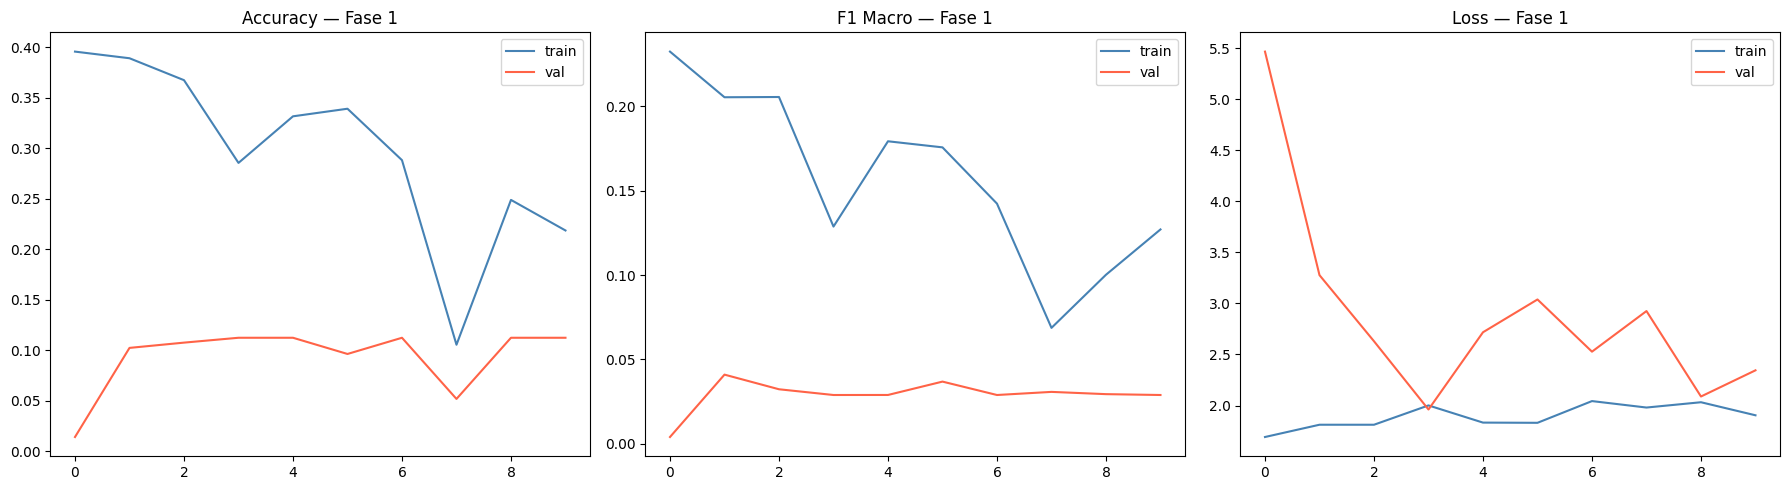

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history1.history['accuracy'],     label='train', color='steelblue')
axes[0].plot(history1.history['val_accuracy'], label='val',   color='tomato')
axes[0].set_title('Accuracy — Fase 1'); axes[0].legend()

axes[1].plot(history1.history['macro_f1'],     label='train', color='steelblue')
axes[1].plot(history1.history['val_macro_f1'], label='val',   color='tomato')
axes[1].set_title('F1 Macro — Fase 1'); axes[1].legend()

axes[2].plot(history1.history['loss'],     label='train', color='steelblue')
axes[2].plot(history1.history['val_loss'], label='val',   color='tomato')
axes[2].set_title('Loss — Fase 1'); axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'v4_fase1_curvas.png'), dpi=150)
plt.show()

## 8 · Fase 2a — Fine-tuning (últimas 50 capas)

In [ ]:
model_path = os.path.join(MODELS_DIR, 'densenet201_v4_phase1_best.keras')

if os.path.exists(model_path):
    print(f'Cargando modelo guardado desde: {model_path}')
    model = tf.keras.models.load_model(
        model_path,
        custom_objects={'FocalLoss': FocalLoss}
    )
else:
    print('⚠️ No se encontró el archivo en Drive. Usando el modelo de la memoria activa de la sesión...')
    # Usamos la variable 'model' existente en la memoria si no se pudo cargar del disco
    if 'model' not in locals():
        raise ValueError("No se encontró el modelo ni en Drive ni en la memoria local de la sesión. Por favor ejecuta de nuevo la Fase 1.")

base_model = model.get_layer('densenet201')

base_model.trainable = True
total_layers = len(base_model.layers)
freeze_until = total_layers - UNFREEZE_PHASE2A
for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= freeze_until)

trainable_now = sum(1 for l in base_model.layers if l.trainable)
print(f'Capas DenseNet: {total_layers} total, {trainable_now} entrenables')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2A),
    loss=focal_loss_fn,
    metrics=['accuracy', tf.keras.metrics.F1Score(average='macro', name='macro_f1')]
)

callbacks_2a = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v4_phase2a_best.keras'),
        monitor='val_macro_f1', mode='max', save_best_only=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_macro_f1', mode='max', factor=0.5, patience=4, min_lr=1e-7, verbose=1
    ),
    EarlyStopping(
        monitor='val_macro_f1', mode='max', patience=8,
        restore_best_weights=True, verbose=1
    ),
]

print(f'\nCompilado para Fase 2a: lr={LR_PHASE2A}, monitoreo=val_macro_f1')

Cargando modelo guardado desde: /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase1_best.keras
Capas DenseNet: 707 total, 50 entrenables

Compilado para Fase 2a: lr=1e-05, monitoreo=val_macro_f1


In [ ]:
print('=' * 60)
print('FASE 2a — Fine-tuning (últimas 50 capas descongeladas)')
print('=' * 60)

history2a = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2A,
    validation_data=val_ds,
    callbacks=callbacks_2a,
    verbose=1
)

best_f1_2a = max(history2a.history['val_macro_f1'])
print(f'\nFase 2a — Mejor val_macro_f1: {best_f1_2a:.4f} ({best_f1_2a*100:.2f}%)')

FASE 2a — Fine-tuning (últimas 50 capas descongeladas)
Epoch 1/20
    300/Unknown 118s 266ms/step - accuracy: 0.0147 - loss: 0.2596 - macro_f1: 0.0092
Epoch 1: val_macro_f1 improved from None to 0.03240, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase2a_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase2a_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 148s 366ms/step - accuracy: 0.0728 - loss: 0.1341 - macro_f1: 0.0351 - val_accuracy: 0.1124 - val_loss: 0.3019 - val_macro_f1: 0.0324 - learning_rate: 1.0000e-05
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.0163 - loss: 0.2454 - macro_f1: 0.0124
Epoch 2: val_macro_f1 did not improve from 0.03240
300/300 ━━━━━━━━━━━━━━━━━━━━ 128s 328ms/step - accuracy: 0.0719 - loss: 0.1216 - macro_f1: 0.0385 - val_accuracy: 0.1124 - val_loss: 0.3126 - val_macro_f1: 0.0323 - learning_rate: 1.0000e-05
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 

## 9 · Fase 2b — Fine-tuning profundo (últimas 100 capas)

In [ ]:
model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'densenet201_v4_phase2a_best.keras'),
    custom_objects={'FocalLoss': FocalLoss}
)
base_model = model.get_layer('densenet201')

base_model.trainable = True
total_layers = len(base_model.layers)
freeze_until = total_layers - UNFREEZE_PHASE2B
for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= freeze_until)

trainable_now = sum(1 for l in base_model.layers if l.trainable)
print(f'Capas DenseNet: {total_layers} total, {trainable_now} entrenables')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2B),
    loss=focal_loss_fn,
    metrics=['accuracy', tf.keras.metrics.F1Score(average='macro', name='macro_f1')]
)

callbacks_2b = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v4_phase2b_best.keras'),
        monitor='val_macro_f1', mode='max', save_best_only=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_macro_f1', mode='max', factor=0.5, patience=4, min_lr=1e-8, verbose=1
    ),
    EarlyStopping(
        monitor='val_macro_f1', mode='max', patience=8,
        restore_best_weights=True, verbose=1
    ),
]

print(f'\nCompilado para Fase 2b: lr={LR_PHASE2B}, monitoreo=val_macro_f1')

Capas DenseNet: 707 total, 100 entrenables

Compilado para Fase 2b: lr=5e-06, monitoreo=val_macro_f1


In [ ]:
print('=' * 60)
print('FASE 2b — Fine-tuning profundo (últimas 100 capas descongeladas)')
print('=' * 60)

history2b = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2B,
    validation_data=val_ds,
    callbacks=callbacks_2b,
    verbose=1
)

best_f1_2b = max(history2b.history['val_macro_f1'])
print(f'\nFase 2b — Mejor val_macro_f1: {best_f1_2b:.4f} ({best_f1_2b*100:.2f}%)')

FASE 2b — Fine-tuning profundo (últimas 100 capas descongeladas)
Epoch 1/20
    300/Unknown 135s 297ms/step - accuracy: 0.1883 - loss: 0.0726 - macro_f1: 0.1035
Epoch 1: val_macro_f1 improved from None to 0.14884, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase2b_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase2b_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 165s 400ms/step - accuracy: 0.1973 - loss: 0.0511 - macro_f1: 0.1089 - val_accuracy: 0.4755 - val_loss: 0.0537 - val_macro_f1: 0.1488 - learning_rate: 5.0000e-06
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.1665 - loss: 0.0737 - macro_f1: 0.0945
Epoch 2: val_macro_f1 improved from 0.14884 to 0.15117, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase2b_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v4_phase2b_best.keras
300/30

## 10 · Curvas de entrenamiento combinadas

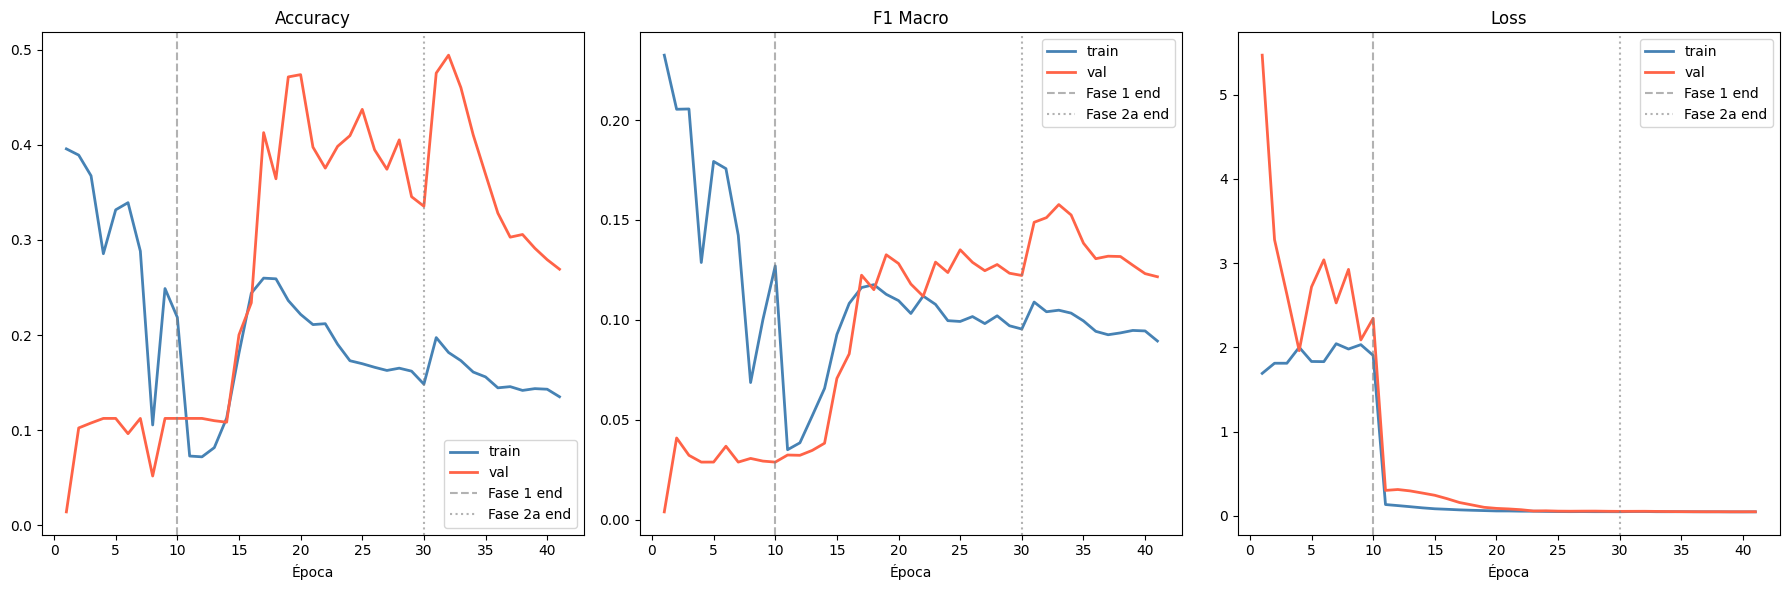

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

acc_all   = history1.history['accuracy']   + history2a.history['accuracy']   + history2b.history['accuracy']
vacc_all  = history1.history['val_accuracy'] + history2a.history['val_accuracy'] + history2b.history['val_accuracy']
f1_all    = history1.history['macro_f1']   + history2a.history['macro_f1']   + history2b.history['macro_f1']
vf1_all   = history1.history['val_macro_f1'] + history2a.history['val_macro_f1'] + history2b.history['val_macro_f1']
loss_all  = history1.history['loss']       + history2a.history['loss']       + history2b.history['loss']
vloss_all = history1.history['val_loss']   + history2a.history['val_loss']   + history2b.history['val_loss']

ep = range(1, len(acc_all) + 1)
ep1_end  = len(history1.history['accuracy'])
ep2a_end = ep1_end + len(history2a.history['accuracy'])

for ax, train_vals, val_vals, title in [
    (axes[0], acc_all,  vacc_all,  'Accuracy'),
    (axes[1], f1_all,   vf1_all,   'F1 Macro'),
    (axes[2], loss_all, vloss_all, 'Loss'),
]:
    ax.plot(ep, train_vals, label='train', color='steelblue', linewidth=2)
    ax.plot(ep, val_vals,   label='val',   color='tomato',    linewidth=2)
    ax.axvline(ep1_end,  color='gray', linestyle='--', alpha=0.6, label='Fase 1 end')
    ax.axvline(ep2a_end, color='gray', linestyle=':',  alpha=0.6, label='Fase 2a end')
    ax.set_title(title); ax.legend(); ax.set_xlabel('Época')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'v4_curvas_completas.png'), dpi=150)
plt.show()

## 11 · Evaluación en conjunto de test

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import seaborn as sns

best_model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'densenet201_v4_phase2b_best.keras'),
    custom_objects={'FocalLoss': FocalLoss}
)

y_pred_probs = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test

print('\nReporte de clasificación:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

41/41 ━━━━━━━━━━━━━━━━━━━━ 30s 534ms/step

Reporte de clasificación:
              precision    recall  f1-score   support

       akiec       0.02      0.07      0.04        42
         bcc       0.04      0.06      0.05        67
         bkl       0.18      0.15      0.16       142
          df       0.00      0.00      0.00        14
         mel       0.20      0.19      0.20       144
          nv       0.67      0.59      0.63       858
        vasc       0.00      0.00      0.00        18

    accuracy                           0.44      1285
   macro avg       0.16      0.15      0.15      1285
weighted avg       0.49      0.44      0.46      1285



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


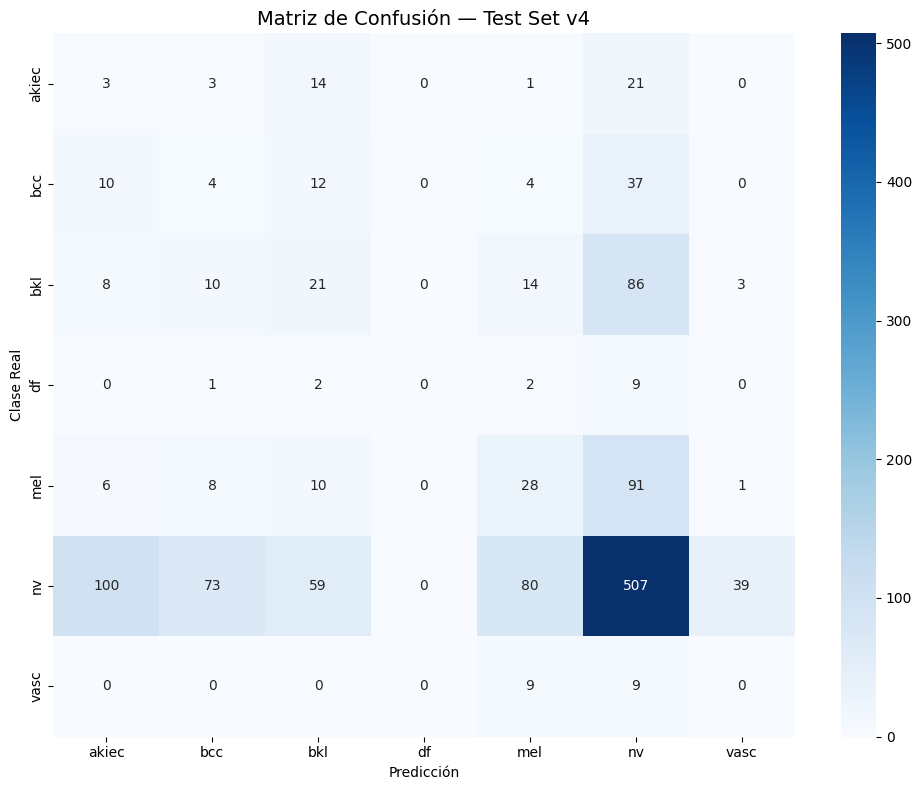

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
plt.title('Matriz de Confusión — Test Set v4', fontsize=14)
plt.ylabel('Clase Real'); plt.xlabel('Predicción')
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'v4_confusion_matrix.png'), dpi=150)
plt.show()

## 12 · Resumen de resultados

In [ ]:
acc = accuracy_score(y_true, y_pred)
f1  = f1_score(y_true, y_pred, average='macro')

print('=' * 55)
print('RESULTADOS FINALES — v4')
print('=' * 55)
print(f'  Val F1 Macro Fase 1 : {best_f1_p1*100:.2f}%')
print(f'  Val F1 Macro Fase 2a: {best_f1_2a*100:.2f}%')
print(f'  Val F1 Macro Fase 2b: {best_f1_2b*100:.2f}%')
print(f'  Test Accuracy Final : {acc*100:.2f}%')
print(f'  F1-Score (macro)    : {f1*100:.2f}%')
print('=' * 55)

print('\nComparativa:')
print(f'  v1  : 54.33% acc / F1 no reportado (balanceo falso)')
print(f'  v2  : 34.35% val_acc / F1 no reportado')
print(f'  v3  : 66.77% acc / 11.44% F1 (predecía solo nv)')
print(f'  v4  : {acc*100:.2f}% acc / {f1*100:.2f}% F1  ← este')

RESULTADOS FINALES — v4
  Val F1 Macro Fase 1 : 4.09%
  Val F1 Macro Fase 2a: 13.51%
  Val F1 Macro Fase 2b: 15.77%
  Test Accuracy Final : 43.81%
  F1-Score (macro)    : 15.29%

Comparativa:
  v1  : 54.33% acc / F1 no reportado (balanceo falso)
  v2  : 34.35% val_acc / F1 no reportado
  v3  : 66.77% acc / 11.44% F1 (predecía solo nv)
  v4  : 43.81% acc / 15.29% F1  ← este
